# NB5 · Downstream test: does type-aware cleaning matter?

Guide section "Downstream forecasting evaluation" (eq. 19–20), RQ4, Table 8 and Fig 12. Southern system (15 zones, 10-min steps).

**Cleaning strategies.** They act on flagged zone-steps: dead, hold or linear-fill states inside a qualifying rule zone run.

| Strategy | Artefacts (A1–A3) | Grid events (G1–G5) |
|---|---|---|
| S0 raw | kept | kept |
| S1 naive | linearly interpolated | linearly interpolated (outages erased) |
| S2 typed (ours) | imputed with x̂ (eq. 1), scaled to join the series at both edges | kept, with an event indicator the forecaster sees, excluded from the training loss |
| S3 oracle | as S2, with the true types | as S2, with the true types (injected data only) |

- **Labels on the real data:** the fused labels of the main-detector catalogue (`results/main_detector/p_type_south.csv`, NB4 §8b).
- **Labels on injected data:** the label model's arg max (it matches fusion there, F46).
- **Not changed by any strategy:** items labelled N, clock items and detector-only candidates are left as recorded. A4 stamps are not re-aligned: timestamps stay as recorded (D11).

**Forecasters.**
- A global LightGBM direct forecaster per horizon: 1 h (6 steps) and 1 day (144 steps), rolling origin. Inputs: zone-scaled lags, same-time-of-day lags, the event indicator and target-time calendar.
- A model-free reference on the same cleaned series: persistence at 1 h, seasonal naive (one day earlier) at 1 day.
- They are trained before 1 Jan 2024 and scored on **1 Jan – 24 May 2024** (the guide's test period).
- Scoring uses only zone-steps that every strategy treats as normal (no flagged state, rule item, detector-only candidate or injected event). It compares with the recorded values.
- **Metrics:** MAE, RMSE (A), MASE (eq. 19, seasonal-naive scale), sMAPE.
- **Diebold–Mariano test** (eq. 20) on the per-step scaled absolute loss summed over the scored zones (so its mean follows the pooled MASE difference), with a Newey–West variance (lag = horizon).
- Also scored separately: the subset of steps whose zone had a flagged state in the 2 days before. There the history the forecaster reads contains anomalies.

**Outage statistics** (SAIDI-style check): zone-hours and counts of outages under "every dead state is an outage" (what S0 reports and S1 erases) and under the typed labels (S2), against the injected truth (S3).

**Runtime:** about 10 min for the real data plus about 8 min per injected dataset on 8 CPU cores. Outputs are cached in `results/downstream_v1/`, so the notebook resumes. Decisions: D64–D66.

In [1]:
import sys, subprocess, json, time
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm==4.6.0", "PyWavelets", "statsmodels", "openpyxl"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/grid-event-or-data-artefact")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import lightgbm
import rules_v1 as R1, detector as D, label_model as LM, benchmark as B, inject as INJ, downstream as DS
from viz import COL, savefig

INJ_SETS = [(0.03, 0), (0.03, 1), (0.03, 2), (0.07, 0)]   # NB4 test datasets reused for the oracle and the outage truth
SEED = 0
XLSX = ROOT / "data" / "raw" / "Data Morocco.xlsx"
OUT = ROOT / "results" / "downstream_v1"; (OUT / "injected").mkdir(parents=True, exist_ok=True)
FIG = ROOT / "results" / "figures"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print("ROOT =", ROOT, "| lightgbm", lightgbm.__version__)
T0 = time.time()

ROOT = C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact | lightgbm 4.6.0


## 1. Real data: flagged steps, typed masks, scoring area

In [2]:
res = R1.build(XLSX)
P = D.build_panel(res["data"], res["exp"], res["masks"], "south")
XH = DS.exp_panel(res["exp"], P)
FLAG = DS.run_mask(P, res["zone_runs"])
cat = pd.read_csv(ROOT / "results" / "main_detector" / "p_type_south.csv", parse_dates=["start", "end"])
rule_lab = cat[cat.source == "rule"][["start", "end", "zones", "label"]]
ART, GRID = DS.typed_masks(P, FLAG, rule_lab)
items = res["items"]; south_items = items[items.system == "south"]
ANY_ITEM = DS.span_mask(P, south_items)                         # every rule item, all kinds
DETONLY = DS.span_mask(P, cat[cat.source == "detector"])
NORMAL = ~FLAG & ~ANY_ITEM & ~DETONLY & P["x"].notna()
idx = P["x"].index
print(f"flagged zone-steps {FLAG.to_numpy().mean():.4f}; artefact {ART.to_numpy().sum()}, grid {GRID.to_numpy().sum()} zone-steps;"
      f" normal {NORMAL.to_numpy().mean():.3f}")
print("labels of south rule items:", rule_lab.label.value_counts().to_dict())

flagged zone-steps 0.0122; artefact 14437, grid 1764 zone-steps; normal 0.982
labels of south rule items: {'A3': 91, 'G4': 57, 'A2': 57, 'G3': 17, 'A1': 3, 'G2': 1}


## 2. Outage statistics on the real data (F26 revisited)
A naive count treats every dead state (zero or noise floor, ≥ 30 min) as an outage. The typed count keeps only dead steps inside items labelled G. There is no truth on the real data, so §4 does the same on injected data.

In [3]:
DEAD = P["states"]["dead"] & FLAG
naive_z, naive = DS.outage_stats(P, DEAD)
typed_z, typed = DS.outage_stats(P, DEAD & GRID)
art_z, art = DS.outage_stats(P, DEAD & ART)
out_real = naive_z.rename(columns={"zone_hours": "naive_zone_hours", "outages": "naive_outages"}).merge(
    typed_z.rename(columns={"zone_hours": "typed_zone_hours", "outages": "typed_outages"}), on="code").merge(
    art_z.rename(columns={"zone_hours": "artefact_dead_zone_hours", "outages": "artefact_dead_runs"}), on="code")
out_real["city"] = out_real.code.map(P["city"])
out_real.to_csv(OUT / "outage_real.csv", index=False)
by_city = out_real.groupby("city")[["naive_zone_hours", "typed_zone_hours", "artefact_dead_zone_hours", "naive_outages", "typed_outages"]].sum()
display(by_city.round(1))
lab_dead = {}
for r in rule_lab.itertuples():          # dead zone-hours by label (an item's dead steps)
    m = DS.span_mask(P, pd.DataFrame([r._asdict()])) & DEAD
    lab_dead[r.label] = lab_dead.get(r.label, 0) + m.to_numpy().sum() / 6
print("dead zone-hours by item label:", {k: round(v, 1) for k, v in sorted(lab_dead.items())})
print(f"naive: {naive['zone_hours']:.1f} zone-h in {naive['outages']} runs | typed: {typed['zone_hours']:.1f} zone-h in {typed['outages']} runs"
      f" | ratio {naive['zone_hours'] / max(typed['zone_hours'], 1e-9):.2f}")

,naive_zone_hours,typed_zone_hours,artefact_dead_zone_hours,naive_outages,typed_outages
city,,,,,
Boujdour,239.8,21.8,218.0,21,12
Foum eloued,728.7,220.0,508.7,61,40
Laayoune,252.0,52.2,199.8,35,27


dead zone-hours by item label: {'A1': 926.5, 'A2': 0.0, 'A3': 0.0, 'G2': 4.2, 'G3': 201.8, 'G4': 88.0}
naive: 1220.5 zone-h in 117 runs | typed: 294.0 zone-h in 79 runs | ratio 4.15


## 3. Forecasting on the real data (S0, S1, S2)

In [4]:
f_real, f_loss = OUT / "forecast_real.csv", OUT / "loss_real.pkl"
if f_real.exists() and f_loss.exists():
    fc_real = pd.read_csv(f_real); loss_real = pd.read_pickle(f_loss)
else:
    masks = {"S0": (None, None), "S1": (None, None), "S2": (ART, GRID)}
    fc_real, loss_real = DS.forecast_eval(P, FLAG, masks, NORMAL, NORMAL, XH, seed=SEED)
    fc_real.to_csv(f_real, index=False); pd.to_pickle(loss_real, f_loss)
dm_real = DS.dm_table(loss_real); dm_real.to_csv(OUT / "dm_real.csv", index=False)
display(fc_real.pivot_table(index=["model", "horizon", "subset"], columns="strategy", values="MASE").round(4))
display(dm_real.round(4))

strategy                                     S0      S1      S2
model    horizon subset                                        
LightGBM 1 day   after anomaly (2 days)  1.5014  1.2334  1.0608
                 all                     1.1396  1.1153  1.1016
         1 h     after anomaly (2 days)  0.6561  0.6612  0.6130
                 all                     0.6540  0.6567  0.6538
naive    1 day   after anomaly (2 days)  2.2201  1.5530  1.2780
                 all                     1.2184  1.1644  1.1420
         1 h     after anomaly (2 days)  1.0813  1.0594  1.0519
                 all                     0.9508  0.9489  0.9484

,model,horizon,subset,comparison,mean_loss_diff,share_steps_second_better,n_steps,DM,p
0,LightGBM,1 day,after anomaly (2 days),S1 vs S2,0.5526,0.5059,7725,1.2220,0.2217
1,LightGBM,1 day,after anomaly (2 days),S0 vs S2,1.4110,0.5051,7725,1.1929,0.2329
2,LightGBM,1 day,all,S1 vs S2,0.2038,0.5022,20448,1.1568,0.2474
3,LightGBM,1 day,all,S0 vs S2,0.5673,0.5083,20448,1.2562,0.2091
4,LightGBM,1 h,after anomaly (2 days),S1 vs S2,0.1545,0.5376,7725,4.9398,0.0000
5,LightGBM,1 h,after anomaly (2 days),S0 vs S2,0.1381,0.5305,7725,3.7917,0.0001
6,LightGBM,1 h,all,S1 vs S2,0.0427,0.5077,20448,2.3503,0.0188
7,LightGBM,1 h,all,S0 vs S2,0.0032,0.4892,20448,0.1725,0.8631
8,naive,1 day,after anomaly (2 days),S1 vs S2,0.8816,0.0545,7719,1.4098,0.1586
9,naive,1 day,after anomaly (2 days),S0 vs S2,3.0191,0.0606,7719,1.3712,0.1703


## 4. Injected data: the oracle (S3) and the outage truth
NB4's test datasets are regenerated from their seeds and checked against `results/benchmark_v1/runs/*_truth.csv`.
- **On each dataset:** the rules and the label model give the S2 labels; the injected truth gives the S3 labels.
- **Scoring area:** NB4's clean region plus the injected spans, as in NB4.
- **Forecasts:** scored on clean steps outside every injected event (truth = the real series there).
- **Outages:** counted inside the same area. Truth = injected G1–G4 core spans.

In [5]:
CLEAN = B.clean_region(P, None)
INJECTOR = INJ.Injector(res["data"], res["exp"], CLEAN, INJ.zone_map(res["data"], B.SOUTH, R1.CITY_SHORT))
GRID_T = ("G1", "G2", "G3", "G4", "U_SHOCK", "U_PARTIAL")
for rate, seed in INJ_SETS:
    tag = f"r{int(round(rate * 100)):02d}_s{seed:02d}"
    if (OUT / "injected" / f"{tag}_forecast.csv").exists():
        continue
    t = time.time()
    data_inj, truth = INJECTOR.sample(np.ones(len(idx), bool), rate, np.random.default_rng([int(round(rate * 1000)), seed]))
    stored = pd.read_csv(ROOT / "results" / "benchmark_v1" / "runs" / f"{tag}_truth.csv", parse_dates=["start"])
    assert len(stored) == len(truth) and (stored.start.values == truth.start.values).all(), f"{tag}: differs from NB4"
    r = R1.build_from_data(res["raw"], data_inj)
    it = r["items"]; votes = r["votes"].set_index("item_id")
    q = LM.DawidSkene().fit(votes, it, R1.RULE_KIND).q_; q.index = it.item_id.values
    ev = it[(it.system == "south") & it.kind.isin(["dead", "fill"])].copy()
    ev["label"] = q.loc[ev.item_id].idxmax(axis=1).values
    Pi = D.build_panel(r["data"], r["exp"], r["masks"], "south")
    XHi = DS.exp_panel(r["exp"], Pi)
    FLi = DS.run_mask(Pi, r["zone_runs"])
    ART2, GRID2 = DS.typed_masks(Pi, FLi, ev[["start", "end", "zones", "label"]])
    INJ_ANY = DS.span_mask(Pi, truth, "end_affected")
    ART3 = (ART2 & ~INJ_ANY) | DS.span_mask(Pi, truth[truth.type.isin(DS.ART)])
    GRID3 = ((GRID2 & ~INJ_ANY) | DS.span_mask(Pi, truth[truth.type.isin(GRID_T)], "end_affected")) & ~ART3
    REGION = CLEAN | INJ_ANY
    NORM_i = ~FLi & ~DS.span_mask(Pi, it[it.system == "south"]) & Pi["x"].notna()
    SCORE_i = NORM_i & CLEAN & ~INJ_ANY
    masks = {"S0": (None, None), "S1": (None, None), "S2": (ART2, GRID2), "S3": (ART3, GRID3)}
    fc, loss = DS.forecast_eval(Pi, FLi, masks, NORM_i, SCORE_i, XHi, seed=SEED)
    # outage statistics inside the scoring area
    DEADi = Pi["states"]["dead"] & FLi
    truth_out = DS.span_mask(Pi, truth[truth.type.isin(["G1", "G2", "G3", "G4"])]) & REGION
    rows = []
    for name, m in (("truth (S3)", truth_out), ("naive: every dead state (S0)", DEADi & REGION),
                    ("interpolated away (S1)", DEADi & False), ("typed, label model (S2)", DEADi & GRID2 & REGION)):
        _, tot = DS.outage_stats(Pi, m); rows.append(dict(strategy=name, **tot))
    outage = pd.DataFrame(rows).assign(rate=rate, seed=seed)
    tp = (DEADi & GRID2 & truth_out).to_numpy().sum(); pp = (DEADi & GRID2 & REGION).to_numpy().sum(); tt = truth_out.to_numpy().sum()
    outage["typed_precision_zone_steps"], outage["typed_recall_zone_steps"] = tp / max(pp, 1), tp / max(tt, 1)
    fc.assign(rate=rate, seed=seed).to_csv(OUT / "injected" / f"{tag}_forecast.csv", index=False)
    DS.dm_table(loss).assign(rate=rate, seed=seed).to_csv(OUT / "injected" / f"{tag}_dm.csv", index=False)
    outage.to_csv(OUT / "injected" / f"{tag}_outage.csv", index=False)
    print(f"{tag}: {len(truth)} injected events, {time.time() - t:.0f} s", flush=True)

## 5. Table 8 and the outage check

In [6]:
def load(kind):
    return pd.concat([pd.read_csv(OUT / "injected" / f"r{int(round(r * 100)):02d}_s{s:02d}_{kind}.csv") for r, s in INJ_SETS], ignore_index=True)
fc_inj, dm_inj, out_inj = load("forecast"), load("dm"), load("outage")
t8 = pd.concat([fc_real.assign(data="real"), fc_inj.assign(data="injected")], ignore_index=True)
table8 = t8.groupby(["data", "model", "horizon", "subset", "strategy"])[["MAE", "RMSE", "MASE", "sMAPE"]].mean().round(4)
table8.to_csv(OUT / "table8_forecasting.csv")
display(table8)
dm_all = pd.concat([dm_real.assign(data="real"), dm_inj.assign(data="injected")], ignore_index=True)
dm_all.to_csv(OUT / "table8_dm.csv", index=False)
display(dm_all.groupby(["data", "model", "horizon", "subset", "comparison"]).agg(
    mean_loss_diff=("mean_loss_diff", "mean"), DM=("DM", "mean"), p_max=("p", "max"), p_min=("p", "min"), n=("p", "size")).round(4))
outage_tab = out_inj.groupby(["rate", "strategy"])[["zone_hours", "outages"]].mean().round(1)
outage_tab.to_csv(OUT / "outage_injected.csv"); display(outage_tab)
truth_h = out_inj[out_inj.strategy == "truth (S3)"].set_index(["rate", "seed"]).zone_hours
for s in out_inj.strategy.unique():
    est = out_inj[out_inj.strategy == s].set_index(["rate", "seed"]).zone_hours
    print(f"{s:32s} outage zone-hours / truth: {(est / truth_h).mean():.2f}")
print("typed outage zone-steps: precision", round(out_inj.typed_precision_zone_steps.mean(), 3), "recall", round(out_inj.typed_recall_zone_steps.mean(), 3))

MAE     RMSE    MASE    sMAPE
data     model    horizon subset                 strategy                                   
injected LightGBM 1 day   after anomaly (2 days) S0         8.8632  14.4278  1.2931  14.9531
                                                 S1         8.0548  13.0803  1.1071  13.5171
                                                 S2         7.7602  12.6664  1.0562  13.2530
                                                 S3         7.6907  12.4805  1.0456  13.1630
                          all                    S0         8.4288  13.7014  1.1697  14.4142
                                                 S1         8.0045  13.1022  1.0694  13.7144
                                                 S2         7.8637  12.9812  1.0432  13.5696
                                                 S3         7.8368  12.9022  1.0389  13.5424
                  1 h     after anomaly (2 days) S0         4.3107   8.7476  0.7084   7.2871
                                                 S1         3.8500   6.4758  0.6400   6.2384
                                                 S2         3.7615   6.3198  0.6250   6.1793
                                                 S3         3.6944   6.1669  0.6179   6.0838
                          all                    S0         3.9468   7.3232  0.6518   6.6871
                                                 S1         3.7400   6.3611  0.6219   6.2279
                                                 S2         3.6974   6.2800  0.6134   6.1973
                                                 S3         3.6459   6.1665  0.6081   6.1154
         naive    1 day   after anomaly (2 days) S0        13.6012  28.2981  2.0027  30.0059
                                                 S1         9.5025  17.5168  1.3311  16.1058
                                                 S2        10.9051  22.3457  1.5499  22.3042
                                                 S3        10.2932  20.6195  1.4579  20.5975
                          all                    S0        10.1568  20.5123  1.4008  19.9525
                                                 S1         8.6333  15.5584  1.1553  14.8533
                                                 S2         9.1610  17.6756  1.2355  17.1126
                                                 S3         8.9101  16.8390  1.1987  16.4205
                  1 h     after anomaly (2 days) S0         6.6437  12.7058  0.9994  10.1905
                                                 S1         6.1013  10.0939  0.9128   8.6244
                                                 S2         6.2734  10.9062  0.9403   9.1336
                                                 S3         6.1243  10.1588  0.9164   8.6841
                          all                    S0         6.1403  10.9597  0.9133   9.1615
                                                 S1         5.9342   9.8892  0.8807   8.5713
                                                 S2         5.9981  10.2084  0.8907   8.7548
                                                 S3         5.9427   9.9146  0.8819   8.5919
real     LightGBM 1 day   after anomaly (2 days) S0        10.5328  18.7311  1.5014  17.7006
                                                 S1         9.6283  16.7583  1.2334  15.0808
                                                 S2         8.8914  15.3035  1.0608  14.5508
                          all                    S0         7.8578  13.0652  1.1396  13.6869
                                                 S1         7.7694  12.8383  1.1153  13.4378
                                                 S2         7.7145  12.6919  1.1016  13.3989
                  1 h     after anomaly (2 days) S0         4.2619   8.1914  0.6561   6.9767
                                                 S1         4.2123   7.9188  0.6612   6.8012
                                                 S2         3.9051   6.8908  0.6130   6.4931
                          all                    S0         3.61

mean_loss_diff      DM   p_max   p_min  n
data     model    horizon subset                 comparison                                           
injected LightGBM 1 day   after anomaly (2 days) S0 vs S2            1.6144  3.5135  0.0436  0.0000  4
                                                 S1 vs S2            0.3422  1.8444  0.7706  0.0000  4
                                                 S2 vs S3            0.0764  0.5858  0.6929  0.0286  4
                          all                    S0 vs S2            1.8041  4.6032  0.0018  0.0000  4
                                                 S1 vs S2            0.3739  2.3475  0.6865  0.0000  4
                                                 S2 vs S3            0.0614  0.7347  0.2306  0.0981  4
                  1 h     after anomaly (2 days) S0 vs S2            0.5777  4.8952  0.0004  0.0000  4
                                                 S1 vs S2            0.0970  3.7508  0.1620  0.0000  4
                                                 S2 vs S3            0.0501  2.0847  0.8936  0.0009  4
                          all                    S0 vs S2            0.5478  6.1496  0.0000  0.0000  4
                                                 S1 vs S2            0.1215  5.1781  0.0078  0.0000  4
                                                 S2 vs S3            0.0760  3.4141  0.1674  0.0000  4
         naive    1 day   after anomaly (2 days) S0 vs S2            3.1182  2.4909  0.0563  0.0003  4
                                                 S1 vs S2           -1.5131 -1.8959  0.2649  0.0234  4
                                                 S2 vs S3            0.6707  1.1333  0.7641  0.0742  4
                          all                    S0 vs S2            2.3606  2.4715  0.0579  0.0003  4
                                                 S1 vs S2           -1.1459 -1.8852  0.2659  0.0237  4
                                                 S2 vs S3            0.5242  1.1297  0.7641  0.0759  4
                  1 h     after anomaly (2 days) S0 vs S2            0.4142  2.9495  0.0214  0.0000  4
                                                 S1 vs S2           -0.1907 -2.3785  0.0269  0.0073  4
                                                 S2 vs S3            0.1664  1.9425  0.2088  0.0216  4
                          all                    S0 vs S2            0.3223  2.9480  0.0214  0.0000  4
                                                 S1 vs S2           -0.1426 -2.3776  0.0270  0.0073  4
                                                 S2 vs S3            0.1250  1.9542  0.2089  0.0190  4
real     LightGBM 1 day   after anomaly (2 days) S0 vs S2            1.4110  1.1929  0.2329  0.2329  1
                                                 S1 vs S2            0.5526  1.2220  0.2217  0.2217  1
                          all                    S0 vs S2            0.5673  1.2562  0.2091  0.2091  1
                                                 S1 vs S2            0.2038  1.1568  0.2474  0.2474  1
                  1 h     after anomaly (2 days) S0 vs S2            0.1381  3.7917  0.0001  0.0001  1
                                                 S1 vs S2            0.1545  4.9398  0.0000  0.0000  1
                          all                    S0 vs S2            0.0032  0.1725  0.8631  0.8631  1
                                                 S1 vs S2            0.0427  2.3503  0.0188  0.0188  1
         naive    1 day   after anomaly (2 days) S0 vs S2            3.0191  1.3712  0.1703  0.1703  1
                                                 S1 vs S2            0.8816  1.4098  0.1586  0.1586  1
                          all                    S0 vs S2            1.1400  1.3563  0.1750  0.1750  1
                                                 S1 vs S2            0.3329  1.3936  0.1635  0.1635  1
                  1 h     after anomaly (2 days) S0 vs S2            0.0941  1.9643  0.0495  0.0495  1
                                            

zone_hours  outages
rate strategy                                         
0.03 interpolated away (S1)               0.0      0.0
     naive: every dead state (S0)      3882.9    727.7
     truth (S3)                        2140.3    405.7
     typed, label model (S2)           2891.7    535.0
0.07 interpolated away (S1)               0.0      0.0
     naive: every dead state (S0)      8535.8   1819.0
     truth (S3)                        4503.8    999.0
     typed, label model (S2)           5640.2   1296.0

truth (S3)                       outage zone-hours / truth: 1.00
naive: every dead state (S0)     outage zone-hours / truth: 1.88
interpolated away (S1)           outage zone-hours / truth: 0.00
typed, label model (S2)          outage zone-hours / truth: 1.36
typed outage zone-steps: precision 0.752 recall 0.998


## 6. Fig 12: forecast error by strategy and horizon, and outage-hours error

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/fig12_downstream.png


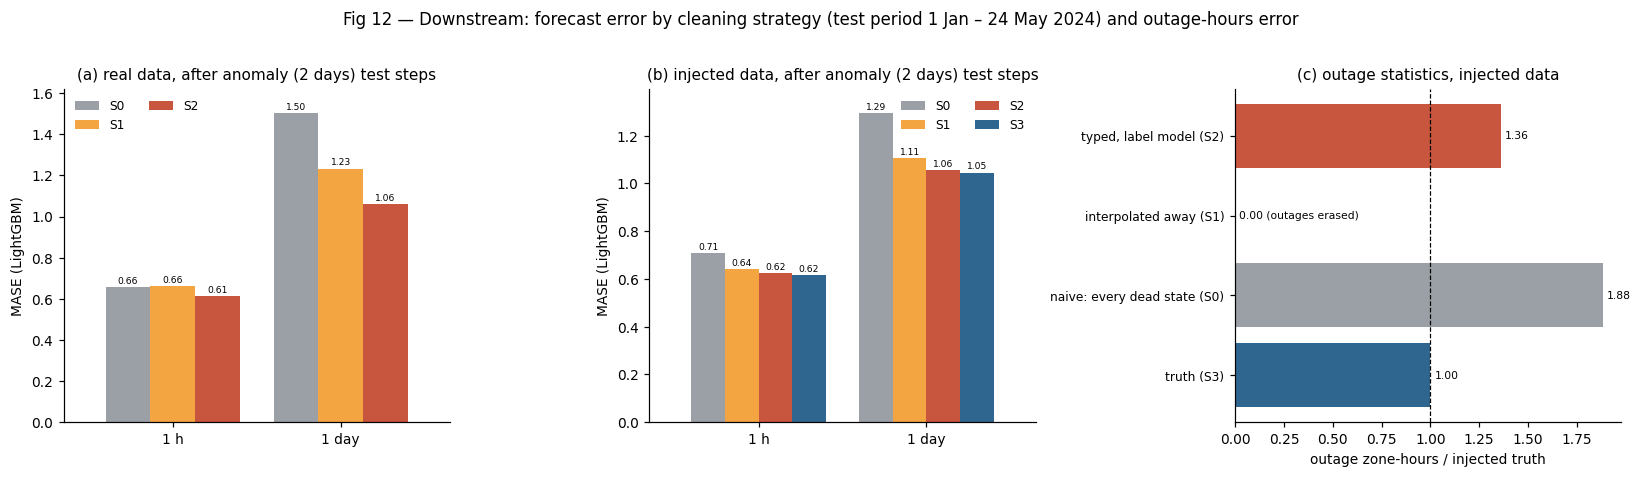

In [7]:
SC = {"S0": "#9AA0A6", "S1": "#F2A541", "S2": "#C8553D", "S3": "#2F6690"}
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (data, sub) in zip(axs[:2], [("real", "after anomaly (2 days)"), ("injected", "after anomaly (2 days)")]):
    g = t8[(t8.data == data) & (t8.subset == sub) & (t8.model == "LightGBM")].groupby(["horizon", "strategy"]).MASE.mean().unstack()
    g = g.reindex(["1 h", "1 day"])
    g.plot.bar(ax=ax, color=[SC[c] for c in g.columns], rot=0, width=0.8)
    ax.set_ylabel("MASE (LightGBM)"); ax.set_xlabel(""); ax.set_title(f"({'ab'[axs.tolist().index(ax)]}) {data} data, {sub} test steps")
    ax.set_ylim(0, g.max().max() * 1.08); ax.legend(fontsize=8, ncol=2)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.2f", fontsize=6, padding=1)
ratio = []
for s in out_inj.strategy.unique():
    est = out_inj[out_inj.strategy == s].set_index(["rate", "seed"]).zone_hours
    ratio.append((s, (est / truth_h).mean()))
lbl, val = zip(*ratio)
axs[2].barh(range(len(val)), val, color=["#2F6690", "#9AA0A6", "#F2A541", "#C8553D"][:len(val)])
axs[2].axvline(1, color="k", lw=.8, ls="--"); axs[2].set_yticks(range(len(val))); axs[2].set_yticklabels(lbl, fontsize=8)
for i, v in enumerate(val):
    axs[2].text(v + 0.02, i, f"{v:.2f}" + (" (outages erased)" if v == 0 else ""), va="center", fontsize=7)
axs[2].set_xlabel("outage zone-hours / injected truth"); axs[2].set_title("(c) outage statistics, injected data")
fig.suptitle("Fig 12 — Downstream: forecast error by cleaning strategy (test period 1 Jan – 24 May 2024) and outage-hours error", y=1.02)
fig.tight_layout(); savefig(fig, FIG, "fig12_downstream"); plt.show()

## 7. Summary

In [8]:
summary = dict(
    outage_real=dict(naive=naive, typed=typed, artefact_dead=art, ratio_naive_to_typed=naive["zone_hours"] / max(typed["zone_hours"], 1e-9),
                     dead_zone_hours_by_label={k: round(v, 1) for k, v in lab_dead.items()}),
    forecast_real={f"{r.model} | {r.horizon} | {r.subset} | {r.strategy}": dict(MAE=round(r.MAE, 4), MASE=round(r.MASE, 4), n=r.n)
                   for r in fc_real.itertuples()},
    dm_real={f"{r.model} | {r.horizon} | {r.subset} | {r.comparison}": dict(DM=round(r.DM, 3), p=r.p, mean_loss_diff=r.mean_loss_diff)
             for r in dm_real.itertuples()},
    outage_injected=out_inj.groupby("strategy")[["zone_hours", "outages"]].mean().round(2).to_dict("index"),
    outage_ratio_to_truth={s: round(float((out_inj[out_inj.strategy == s].set_index(["rate", "seed"]).zone_hours / truth_h).mean()), 3)
                           for s in out_inj.strategy.unique()},
    injected_sets=[f"{r:.0%} seed {s}" for r, s in INJ_SETS], lightgbm_version=lightgbm.__version__, runtime_min=round((time.time() - T0) / 60, 1))
summary = json.loads(json.dumps(summary, default=float))
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary["outage_real"], indent=1)); print(summary["outage_ratio_to_truth"])

{
 "naive": {
  "zone_hours": 1220.4999999999998,
  "outages": 117
 },
 "typed": {
  "zone_hours": 294.0,
  "outages": 79
 },
 "artefact_dead": {
  "zone_hours": 926.4999999999998,
  "outages": 38
 },
 "ratio_naive_to_typed": 4.151360544217686,
 "dead_zone_hours_by_label": {
  "G2": 4.2,
  "G4": 88.0,
  "G3": 201.8,
  "A1": 926.5,
  "A3": 0.0,
  "A2": 0.0
 }
}
{'truth (S3)': 1.0, 'naive: every dead state (S0)': 1.885, 'interpolated away (S1)': 0.0, 'typed, label model (S2)': 1.362}


In [9]:
if IN_COLAB:
    drive.flush_and_unmount()
    print("Drive flushed and unmounted: now press Ctrl+S to save this notebook to Drive")